In [6]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
import numpy as np
import torch
import time

from models import PeriodicFourierMLP_nu, count_parameters, plot_losses
from data import sample_gauge_points_nu, sample_periodic_training_points_nu, to_torch
from lm_train import lm_train_vs
from eval_vs import evaluate_errors

import importlib
import problem_taylor_green_vs as ptg
importlib.reload(ptg)

from plotting_vs import plot_omega_psi_slice

from config import VSConfig
from experiment_log import experiment_log

import csv
from pathlib import Path

cfg = VSConfig()  # Edit seed and sampling counts in config.py.

# CUDA support 
device = torch.device('cpu')
#device = torch.device('cuda')
print('device= ', device)

torch.set_default_dtype(torch.float64)

DTYPE = torch.float64

device=  cpu


In [8]:
from torch.func import functional_call

def make_func_model(model):
    params = dict(model.named_parameters())
    buffers = dict(model.named_buffers())  # usually empty unless BN, etc.

    def func_model(p, x):
        return functional_call(model, (p, buffers), (x,))

    return func_model, params

In [9]:
def run_one_experiment(run_id: int):

    run_seed = np.random.SeedSequence(cfg.seed, spawn_key=(run_id,))
    model_rng, train_rng, gauge_rng, eval_rng = run_seed.spawn(4)
    model_seed = int(model_rng.generate_state(1, dtype=np.uint64)[0])
    torch.manual_seed(model_seed)

    # -----------------------
    # 1) initialize model
    # -----------------------

    model = PeriodicFourierMLP_nu(
        hidden_dim=cfg.hidden_dim,
        depth=cfg.depth,
        out_dim=2
    ).to(device).to(DTYPE)

    func_model, func_params = make_func_model(model)
    print(cfg)
    print(model)
    print("Model dtype:", next(model.parameters()).dtype)
    print("Trainable parameters:", count_parameters(model))
    
    X_inner, X_initial = sample_periodic_training_points_nu(
        cfg.x_min, cfg.x_max, cfg.y_min, cfg.y_max, cfg.t_min, cfg.t_max, cfg.nu_min, cfg.nu_max,
        N_interior=cfg.N_interior,
        N_initial=cfg.N_initial,
        seed=int(train_rng.generate_state(1, dtype=np.uint64)[0]),
    )

    X_gauge = sample_gauge_points_nu(
        cfg.x_min, cfg.x_max, cfg.y_min, cfg.y_max, cfg.t_min, cfg.t_max, cfg.nu_min, cfg.nu_max,
        N_times=cfg.N_gauge_times,
        N_viscosities=cfg.N_gauge_viscosities,
        N_space=cfg.N_gauge_space,
        seed=int(gauge_rng.generate_state(1, dtype=np.uint64)[0]),
    )
    X_inner_t, X_initial_t, X_gauge_t = to_torch(
        X_inner, X_initial, X_gauge,
        device=device, dtype=DTYPE,
        requires_grad=[True, False, False],
    )

    U_initial_np = ptg.exact_omega_np(
        X_initial[:, 0:1],
        X_initial[:, 1:2],
        X_initial[:, 2:3],
        X_initial[:, 3:4],
    )

    omega0_initial_t = torch.tensor(
        U_initial_np,
        device=device,
        dtype=DTYPE,
        requires_grad=False   # IMPORTANT: target
    )

    start = time.perf_counter()

    losses, func_params = lm_train_vs(
        func_model=func_model,
        func_params=func_params,
        X_inner=X_inner_t,
        X_initial=X_initial_t,
        omega0_initial=omega0_initial_t,
        max_steps=cfg.LM_iter,
        mu_init=cfg.mu_init,
        mu_update_every=cfg.mu_update_every,
        div_factor=cfg.div_factor,
        mul_factor=cfg.mul_factor,
        tol=1e-12,
        use_gauge=True,
        gauge_weight=cfg.gauge_weight,
        X_gauge=X_gauge_t,
        verbose_every=100,
    )

    end = time.perf_counter()
    elapsed = end - start
    print(f"LM Wall-clock time: {elapsed:.2f} s")

    plot_losses(losses)

    # Error at the interior points
    error_w_2r, error_w_infr, error_gradpsi_2r, error_gradpsi_infr = evaluate_errors(
        func_model=func_model,
        params=func_params,
        device=device,
        dtype_torch=DTYPE,
        x_min=cfg.x_min, x_max=cfg.x_max,
        y_min=cfg.y_min, y_max=cfg.y_max,
        t_min=cfg.t_min, t_max=cfg.t_max,
        nu_min=cfg.nu_min, nu_max=cfg.nu_max,
        N_val=cfg.N_val,
        N_grad=cfg.N_grad,
        seed=int(eval_rng.generate_state(1, dtype=np.uint64)[0]),
        exact_omega_np=ptg.exact_omega_np,
        exact_psix_np=ptg.exact_psix_np,
        exact_psiy_np=ptg.exact_psiy_np,
    )

    print(
        "\n[Evaluation errors]\n"
        f"  ω  (L2 rel)  : {error_w_2r:.3e}\n"
        f"  ω  (L∞ rel)  : {error_w_infr:.3e}\n"
        f"  ∇ψ (L2 rel)  : {error_gradpsi_2r:.3e}\n"
        f"  ∇ψ (L∞ rel)  : {error_gradpsi_infr:.3e}\n"
    )

    write_header = not csv_path.exists()
    
    with open(csv_path, "a", newline="") as f:
        writer = csv.writer(f)
    
        if write_header:
            writer.writerow(header)
    
        writer.writerow([
            exp_id, run_id,
            cfg.seed, cfg.depth, cfg.hidden_dim, cfg.LM_iter, cfg.nu_min, cfg.nu_max,
            cfg.N_interior, cfg.N_initial, cfg.N_gauge_times, cfg.N_gauge_viscosities, cfg.N_gauge_space,
            cfg.N_val, cfg.N_grad, count_parameters(model), len(losses), elapsed,
            losses[-1],
            error_w_2r, error_w_infr,
            error_gradpsi_2r, error_gradpsi_infr,
        ])
    
    plot_omega_psi_slice(
        func_model=func_model,
        params=func_params,
        t_val=1.0,
        eta_val=np.log(cfg.nu_min),
        x_min=cfg.x_min, x_max=cfg.x_max,
        y_min=cfg.y_min, y_max=cfg.y_max,
        n=256,
        device=device,
        dtype=DTYPE,
    )

    return func_model, func_params



=== Run 0 | 2026-11-25T22:16:10+08:00 ===
VSConfig(seed=None, x_min=0.0, x_max=6.283185307179586, y_min=0.0, y_max=6.283185307179586, t_min=0.0, t_max=1.0, nu_min=0.001, nu_max=1.0, hidden_dim=15, depth=2, N_initial=300, N_interior=2500, gauge_weight=0.01, N_gauge_times=11, N_gauge_viscosities=4, N_gauge_space=256, LM_iter=3001, mu_init=100000.0, mu_update_every=2, div_factor=1.3, mul_factor=3.0, N_val=10000, N_grad=10000)
PeriodicFourierMLP_nu(
  (hidden): Sequential(
    (0): Linear(in_features=6, out_features=15, bias=True)
    (1): Tanh()
    (2): Linear(in_features=15, out_features=15, bias=True)
    (3): Tanh()
  )
  (out): Linear(in_features=15, out_features=2, bias=False)
)
Model dtype: torch.float64
Trainable parameters: 375
Total number of training points: 2800
J shape: torch.Size([5344, 375])
L shape: torch.Size([5344])
Parameter count P: 375
Residual count M: 5344
step     0 | loss=1.34232e+00 | mu=1.000e+05
step   100 | loss=2.68196e-01 | mu=2.008e-01
step   200 | loss=1.

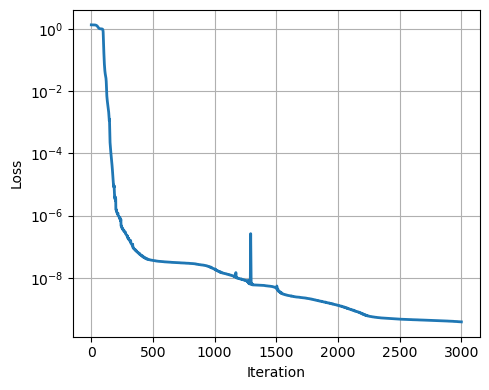


[Evaluation errors]
  ω  (L2 rel)  : 8.020e-06
  ω  (L∞ rel)  : 5.708e-05
  ∇ψ (L2 rel)  : 1.073e-05
  ∇ψ (L∞ rel)  : 5.995e-05



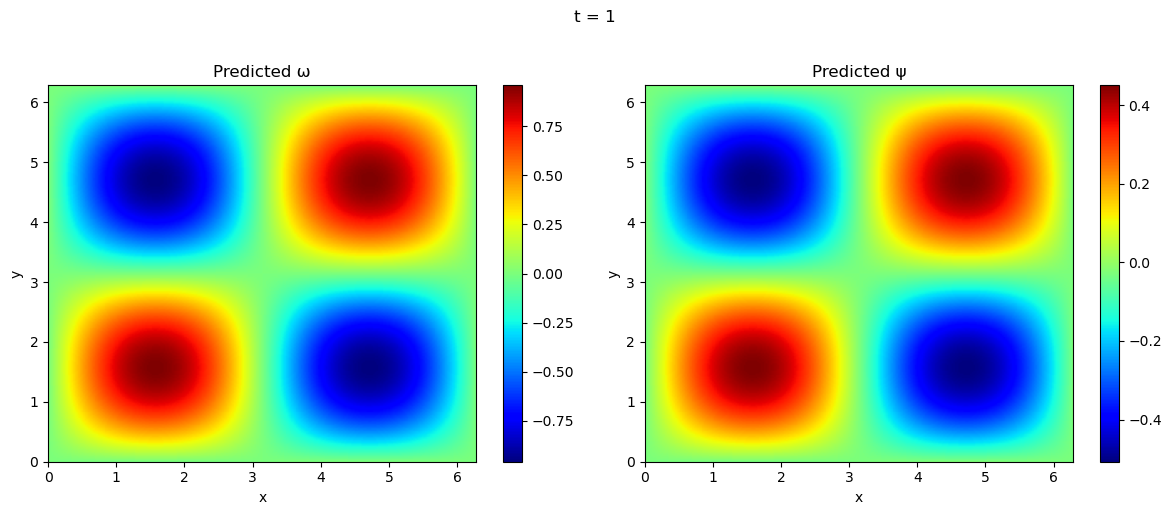


=== Run 1 | 2026-11-25T22:18:33+08:00 ===
VSConfig(seed=None, x_min=0.0, x_max=6.283185307179586, y_min=0.0, y_max=6.283185307179586, t_min=0.0, t_max=1.0, nu_min=0.001, nu_max=1.0, hidden_dim=15, depth=2, N_initial=300, N_interior=2500, gauge_weight=0.01, N_gauge_times=11, N_gauge_viscosities=4, N_gauge_space=256, LM_iter=3001, mu_init=100000.0, mu_update_every=2, div_factor=1.3, mul_factor=3.0, N_val=10000, N_grad=10000)
PeriodicFourierMLP_nu(
  (hidden): Sequential(
    (0): Linear(in_features=6, out_features=15, bias=True)
    (1): Tanh()
    (2): Linear(in_features=15, out_features=15, bias=True)
    (3): Tanh()
  )
  (out): Linear(in_features=15, out_features=2, bias=False)
)
Model dtype: torch.float64
Trainable parameters: 375
Total number of training points: 2800
J shape: torch.Size([5344, 375])
L shape: torch.Size([5344])
Parameter count P: 375
Residual count M: 5344
step     0 | loss=1.23565e+00 | mu=1.000e+05
step   100 | loss=3.71405e-01 | mu=2.008e-01
step   200 | loss=7.

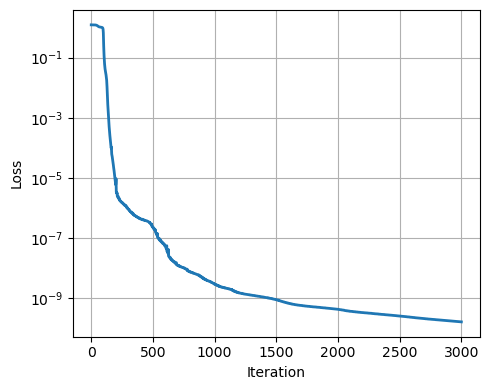


[Evaluation errors]
  ω  (L2 rel)  : 5.173e-06
  ω  (L∞ rel)  : 4.427e-05
  ∇ψ (L2 rel)  : 6.664e-06
  ∇ψ (L∞ rel)  : 5.034e-05



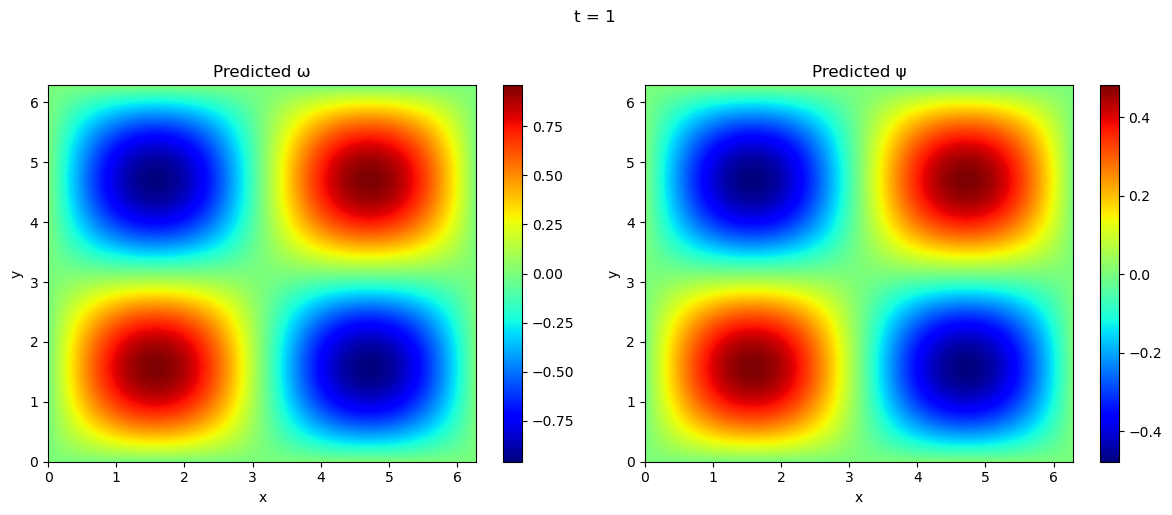


=== Run 2 | 2026-11-25T22:21:14+08:00 ===
VSConfig(seed=None, x_min=0.0, x_max=6.283185307179586, y_min=0.0, y_max=6.283185307179586, t_min=0.0, t_max=1.0, nu_min=0.001, nu_max=1.0, hidden_dim=15, depth=2, N_initial=300, N_interior=2500, gauge_weight=0.01, N_gauge_times=11, N_gauge_viscosities=4, N_gauge_space=256, LM_iter=3001, mu_init=100000.0, mu_update_every=2, div_factor=1.3, mul_factor=3.0, N_val=10000, N_grad=10000)
PeriodicFourierMLP_nu(
  (hidden): Sequential(
    (0): Linear(in_features=6, out_features=15, bias=True)
    (1): Tanh()
    (2): Linear(in_features=15, out_features=15, bias=True)
    (3): Tanh()
  )
  (out): Linear(in_features=15, out_features=2, bias=False)
)
Model dtype: torch.float64
Trainable parameters: 375
Total number of training points: 2800
J shape: torch.Size([5344, 375])
L shape: torch.Size([5344])
Parameter count P: 375
Residual count M: 5344
step     0 | loss=1.04400e+00 | mu=1.000e+05
step   100 | loss=4.40999e-01 | mu=2.008e-01
step   200 | loss=1.

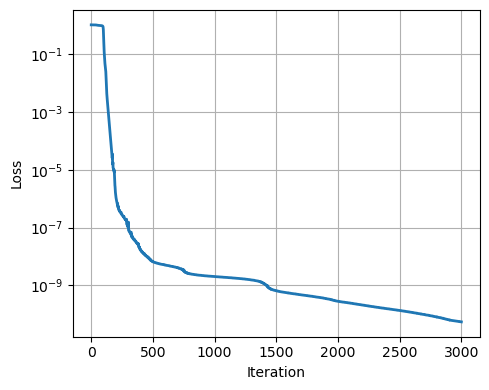


[Evaluation errors]
  ω  (L2 rel)  : 3.210e-06
  ω  (L∞ rel)  : 1.765e-05
  ∇ψ (L2 rel)  : 3.925e-06
  ∇ψ (L∞ rel)  : 2.094e-05



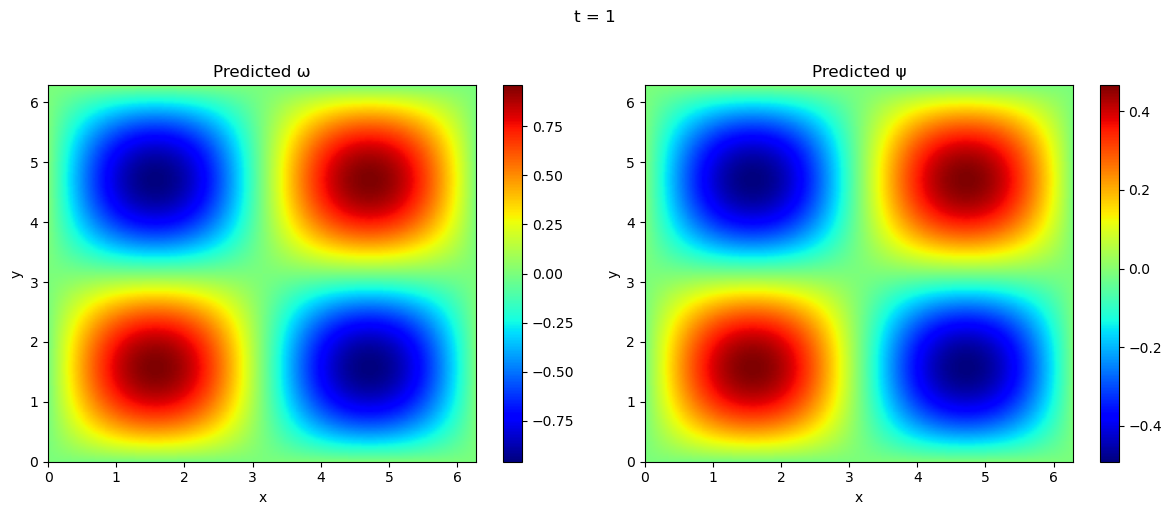


=== Run 3 | 2026-11-25T22:23:59+08:00 ===
VSConfig(seed=None, x_min=0.0, x_max=6.283185307179586, y_min=0.0, y_max=6.283185307179586, t_min=0.0, t_max=1.0, nu_min=0.001, nu_max=1.0, hidden_dim=15, depth=2, N_initial=300, N_interior=2500, gauge_weight=0.01, N_gauge_times=11, N_gauge_viscosities=4, N_gauge_space=256, LM_iter=3001, mu_init=100000.0, mu_update_every=2, div_factor=1.3, mul_factor=3.0, N_val=10000, N_grad=10000)
PeriodicFourierMLP_nu(
  (hidden): Sequential(
    (0): Linear(in_features=6, out_features=15, bias=True)
    (1): Tanh()
    (2): Linear(in_features=15, out_features=15, bias=True)
    (3): Tanh()
  )
  (out): Linear(in_features=15, out_features=2, bias=False)
)
Model dtype: torch.float64
Trainable parameters: 375
Total number of training points: 2800
J shape: torch.Size([5344, 375])
L shape: torch.Size([5344])
Parameter count P: 375
Residual count M: 5344
step     0 | loss=9.92192e-01 | mu=1.000e+05
step   100 | loss=8.84581e-01 | mu=2.008e-01
step   200 | loss=6.

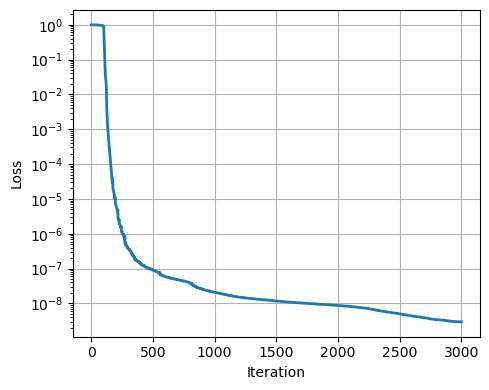


[Evaluation errors]
  ω  (L2 rel)  : 3.719e-05
  ω  (L∞ rel)  : 3.404e-04
  ∇ψ (L2 rel)  : 3.966e-05
  ∇ψ (L∞ rel)  : 2.547e-04



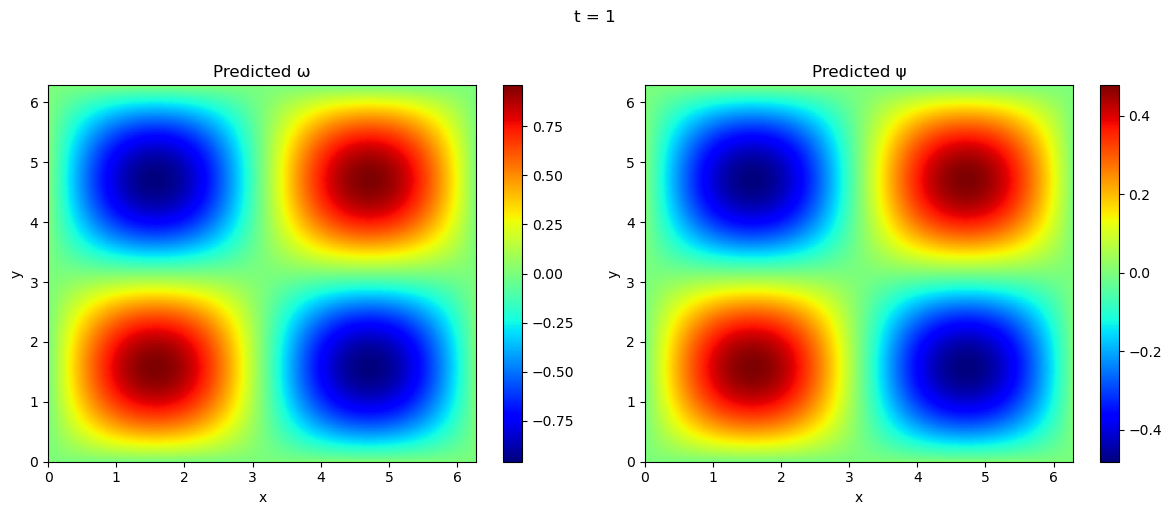

In [10]:
csv_path = Path("VS_ex3_nu_lm.csv")
exp_id = "TG_periodic_nu_ex3"

header = [
    "exp_id", "run_id",
    "seed", "depth", "hidden_dim", "LM_iter", "nu_min", "nu_max",
    "N_interior", "N_initial", "N_gauge_times", "N_gauge_viscosities", "N_gauge_space",
    "N_val", "N_grad", "trainable_parameters", "lm_steps", "lm_seconds",
    "final_loss",
    "err_w_L2", "err_w_Linf",
    "err_gradpsi_L2", "err_gradpsi_Linf",
]

for run_id in range(4):
    with experiment_log(csv_path, run_id):
        last_func_model, last_func_params = run_one_experiment(run_id)